# Almaty Air Pollution Analysis
## Task 3 Research results and data analysis
This notebook reprocesses the original benchmark logs and exports all figures.
The environmental sample has 8 rows; repeated rows are synthetic performance loads.
No environmental causal effect or fitted ML model is claimed.

Two separate timing scopes are retained: full Python subprocess execution and
in-process method calculation. Warm-up exclusion does not remove interpreter
startup from each subprocess. Restart the kernel and run all cells in order.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
from pathlib import Path
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src/process_data.py').is_file(), 'Run from the repository or notebooks folder'
sys.path.insert(0, str(ROOT))
from src.process_data import load_data, summarize
from src.process_comparison import summarize_comparison
from src.visualize import create_figures, create_load_comparison

print('Python:', sys.version.split()[0])
print({name: metadata.version(name) for name in ['numpy', 'pandas', 'matplotlib']})
print('Bootstrap seed: 42; resamples: 10000')

Python: 3.12.3
{'numpy': '1.26.3', 'pandas': '2.2.0', 'matplotlib': '3.8.2'}
Bootstrap seed: 42; resamples: 10000


C:\Users\Dimash\AppData\Local\Temp\ipykernel_15420\1842245647.py:8: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Data ingestion and warm-up filtering
Validate phases, JSON boolean outcomes, duplicate identifiers and finite latencies.
All evaluation attempts enter the error-rate denominator; only successful attempts
enter latency calculations. Raw measurements are not overwritten by this notebook.

In [2]:
runs = load_data(ROOT / 'data/raw/test_run.jsonl')
comparison = load_data(ROOT / 'data/raw/method_comparison.jsonl', comparison=True)
for name, frame in [('Subprocess', runs), ('Method comparison', comparison)]:
    print(name, frame.groupby(['phase', 'success']).size().to_dict())
display(runs.head())
display(comparison.head())

Subprocess {('evaluation', True): 30, ('warmup', True): 5}
Method comparison {('evaluation', True): 240, ('warmup', True): 40}


,run_id,phase,latency_ms,success,return_code,timestamp
0,1,warmup,681.079,True,0,2026-10-28T21:21:59.680223+00:00
1,2,warmup,721.061,True,0,2026-10-28T21:22:00.400889+00:00
2,3,warmup,669.095,True,0,2026-10-28T21:22:01.070843+00:00
3,4,warmup,603.863,True,0,2026-10-28T21:22:01.674384+00:00
4,5,warmup,592.148,True,0,2026-10-28T21:22:02.266779+00:00


,method,load_size,run_id,phase,latency_ms,success,result,error,timestamp
0,Baseline,8,1,warmup,0.6546,True,75.9,None,2026-10-28T21:39:23.867274+00:00
1,Baseline,8,2,warmup,0.5992,True,75.9,None,2026-10-28T21:39:23.868273+00:00
2,Baseline,8,3,warmup,0.4647,True,75.9,None,2026-10-28T21:39:23.868273+00:00
3,Baseline,8,4,warmup,0.3894,True,75.9,None,2026-10-28T21:39:23.868273+00:00
4,Baseline,8,5,warmup,0.4580,True,75.9,None,2026-10-28T21:39:23.869270+00:00


## Statistical aggregation
Use sample SD (ddof=1), linear-interpolated percentiles, and percentile bootstrap
95% confidence intervals for the mean. These intervals describe mean uncertainty,
not the range containing 95% of individual runs. The 30-trial p99 is near the
maximum and is only a descriptive tail estimate.

In [3]:
process_summary = pd.DataFrame([summarize(runs)])
method_summary = summarize_comparison(comparison)
processed = ROOT / 'data/processed'
processed.mkdir(parents=True, exist_ok=True)
process_summary.to_csv(processed / 'metrics_summary.csv', index=False)
method_summary.to_csv(processed / 'method_comparison_summary.csv', index=False)
display(process_summary.round(4))
display(method_summary.round(4))

,total_runs,warmup_runs,evaluation_runs,successful_runs,error_rate_percent,mean_ms,median_ms,std_ms,p25_ms,p75_ms,p95_ms,p99_ms,ci95_lower_ms,ci95_upper_ms
0,35,5,30,30,0.0,616.797,609.673,53.4941,579.3933,651.8253,717.0852,740.5285,598.5582,636.767


,method,load_size,total_runs,warmup_runs,evaluation_runs,successful_runs,error_rate_percent,mean_ms,median_ms,std_ms,p25_ms,p75_ms,p95_ms,p99_ms,ci95_lower_ms,ci95_upper_ms
0,Baseline,8,35,5,30,30,0.0,0.5874,0.5428,0.2061,0.4104,0.6634,1.0134,1.1486,0.5192,0.6631
1,Proposed,8,35,5,30,30,0.0,0.5099,0.4157,0.2520,0.3885,0.4872,0.9289,1.3838,0.4339,0.6118
2,Baseline,80,35,5,30,30,0.0,2.7543,2.6804,0.1863,2.6611,2.7223,3.1831,3.3567,2.6955,2.8252
3,Proposed,80,35,5,30,30,0.0,0.2652,0.2604,0.0160,0.2547,0.2714,0.3009,0.3049,0.2600,0.2711
4,Baseline,800,35,5,30,30,0.0,26.8617,26.2413,3.5314,24.0687,28.8558,32.3806,36.4616,25.6776,28.1587
5,Proposed,800,35,5,30,30,0.0,0.3486,0.2928,0.1640,0.2552,0.3531,0.7269,0.8918,0.2978,0.4122
6,Baseline,8000,35,5,30,30,0.0,320.4048,281.2171,90.5693,240.6733,416.3752,457.5772,489.7494,289.5040,352.1894
7,Proposed,8000,35,5,30,30,0.0,0.5545,0.5364,0.1720,0.4306,0.5995,0.8704,1.1110,0.4997,0.6202


## Numerical equivalence and comparison
Check the recorded outputs and the current implementations on each workload.
The seasonal difference is a descriptive sample calculation in micrograms per
cubic meter. Speedup is baseline mean divided by proposed mean, without a
confidence interval of its own.

In [4]:
from src.compare_methods import baseline_method, proposed_method
sample = pd.read_csv(ROOT / 'data/sample/almaty_air_sample.csv')
expected = proposed_method(sample)
for size in sorted(comparison['load_size'].unique()):
    workload = pd.concat([sample] * int(np.ceil(size / len(sample))), ignore_index=True).iloc[:size]
    assert np.isclose(baseline_method(workload), proposed_method(workload))
assert np.allclose(comparison.loc[comparison['success'], 'result'], expected)
means = method_summary.pivot(index='load_size', columns='method', values='mean_ms')
means['speedup'] = means['Baseline'] / means['Proposed']
print(f'Descriptive seasonal PM2.5 mean difference: {expected:.2f} ug/m3')
print('Observed method evaluation failures:', int(((comparison.phase == 'evaluation') & ~comparison.success).sum()))
display(means.round(4))

Descriptive seasonal PM2.5 mean difference: 75.90 ug/m3
Observed method evaluation failures: 0


method,Baseline,Proposed,speedup
load_size,,,
8,0.5874,0.5099,1.1520
80,2.7543,0.2652,10.3851
800,26.8617,0.3486,77.0470
8000,320.4048,0.5545,577.7779


## Visualization and export
Each reusable plotting function exports vector PDF and 300 DPI PNG assets and
displays the same figures below. Series use distinct shapes and line styles.
The load plot has logarithmic axes and explicit 95% CI bars and bands.
Boxplot whiskers extend to observations within 1.5 IQR of each quartile.

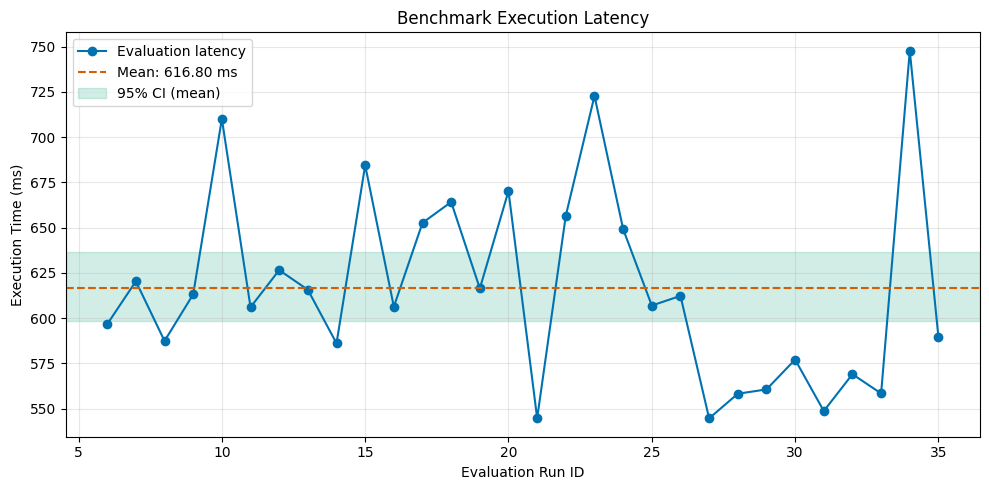

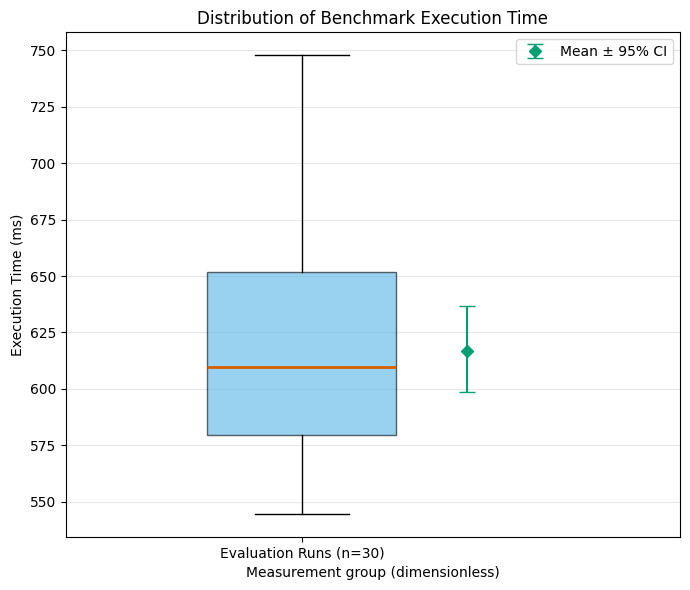

Scientific figures generated successfully!
Saved to: reports\figures


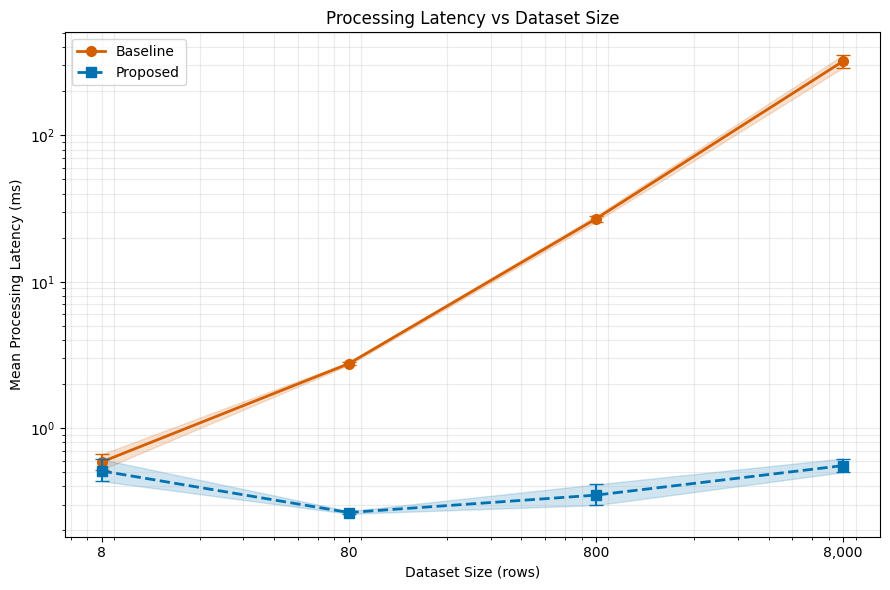

Load comparison figure generated successfully!
Exported figures:
fig1_latency_runs.pdf
fig1_latency_runs.png
fig1_latency_vs_load.pdf
fig1_latency_vs_load.png
fig2_distribution_boxplot.pdf
fig2_distribution_boxplot.png


In [5]:
create_figures(show=True)
create_load_comparison(show=True)
print('Exported figures:')
for path in sorted((ROOT / 'reports/figures').glob('*')):
    print(path.name)

## Results and limitations
The original subprocess mean is about 616.80 ms (30 successful evaluation runs).
At 8,000 rows, the original method means are about 320.405 and 0.555 ms,
giving a descriptive speedup near 577.78. At 8 rows the mean intervals overlap;
the data do not clearly establish a small-load advantage.

The historical measurements were collected sequentially on one machine. CPU state,
cache effects and execution order may confound the comparison. Original hardware
and dependency metadata were not saved; the versions above describe this analysis
rerun. Randomize or alternate method order and save environment metadata in a
future measurement campaign. Zero observed failures does not prove zero failure
probability. Ordinary bootstrap intervals assume approximately independent runs.

The sample PM2.5 contrast is 75.9 ug/m3. Repetition adds computational work, not
independent environmental evidence. Complete class separation and incomplete
heating/calm combinations prevent reliable interaction inference on this sample.
See [the domain model](../docs/domain_model.md) for loss and metric definitions.